# Hackathon 1, statistics.

This project illustrates the statistics part of the course LEPL1109. In the first part of the project, you will study the mortality observed in Belgium. In the second part of the project, you try to predict the electricity consumption in Belgium using climate variables.

## Report content

•	Grades are granted to the members whose names are in the Jupyter notebook. If your name doesn’t appear on the top of the notebook, you’ll get a 0, even though you are in a group on Moodle.

•	The jupyter notebook must be compiled with printed results and next submitted via moodle. The absence of compiled results (or non-printed values) leads to a lower grade.

•	Do not comment your results directly into cells of code. Use instead a Markdown cell. 

•	"Dry" code or results not followed by a minimum of analysis / comments will be penalized.


## Report submission

•	Deadline, see moodle website. Submission after the deadline will not be accepted.

•	To submit your report, go to the section “Hackathon” on Moodle and the subsection “Remise Hackathon 1”. You can upload your work there. Once you are sure that it is your final version, click the button “Envoyer le devoir”. It is important that you don’t forget to click on this button ! 

•	Reports that have not been uploaded through Moodle will not be corrected.


## Names and Noma of participants:

Part. 1: AFRAM Patrick - 42672400

Part. 2: HENNE Alexis - 54762100

Part. 3: SONNET David - 34572300

Part. 4: KEYEUX Titouan - 66022300

Part. 5: VERHAMME Guillaume - 79392400

Part. 6:

# Mortality and climate

In this section, we analyze the relationship between mortality, age groups, and seasons in Belgium using publicly available data from Statbel (see https://statbel.fgov.be/en/about-statbel/what-we-do/visualisations/mortality). The dataset contains the number of deaths recorded over time, disaggregated by age group and observed across different seasons. The objective is to study temporal patterns in mortality and assess the role of seasonal effects. 

## 1. Basic statistics

**1.1)** Load the dataset mortality_climate.csv. Convert the variables *season* and *CD_AGEGROUP* into a categorical variable. 

In [21]:
# Code here
import pandas as pd


df = pd.read_csv("mortality_climate.csv")

df['season'] = df['season'].astype('category') # pour changer en categorical variable
df['CD_AGEGROUP'] = df['CD_AGEGROUP'].astype('category')

**1.2)** Plot the evolution of the number of deaths (*MS_NUM_DEATH*) with respect to age group. What do you observe?

In [22]:
# Code here 


Comments:

**1.3)** Do a scatter plot of the number of deaths (*MS_NUM_DEATH*) by age group.

In [23]:
# Code here 


Comments: 

## 2. Fit of distributions

**2.1)** For the 45–64 age group and the winter season only, fit both a Poisson and a Negative Binomial distribution to the variable 'MS_NUM_DEATH' using a maximum likelihood approach. Plot histograms overlaid with the fitted probability mass functions. Compare the log-likelihoods and select the most appropriate distribution.

In [24]:
# Code here


Comments: 

# 3. Regression

We now aim to assess whether seasonality has an impact on the number of deaths. We consider the following linear model:
$$\log(Y_i) = \beta_0 + \beta_1 X^S_{i1} + \cdots + \beta_3 X^S_{i3} + \beta_4 X^{age}_{i1} + \cdots + \beta_8 X^{age}_{i5}  + \varepsilon_i.$$

where $Y_i$ denotes the number of deaths, $X^S_{ij}$ are dummy variables representing the different seasons, $X^{age}_{ij}$ are dummy variables representing the different age groups, and $\varepsilon_i \sim N(0, \sigma^2)$. 

**3.1)** Why is it more appropriate to use a linear regression on $\log(Y)$ rather than directly on $Y$?

Comments:

**3.2)** Perform a linear regression of the number of deaths on the seasonal and group age covariates. Use the `OLS` function from the *statsmodels* package. Make sure to convert the variable *season* and *CD_AGEGROUP* into dummy variables before fitting the model.

Does seasonality have a significant impact on mortality? Is the mortality similar for each age group? 

In [25]:
# Code here


Comments: 

## 4. Hypothesis test 

We now investigate whether mortality decreases over time by comparing mortality in summer in 2022 and 2025. To this end, we aim to perform the following hypothesis test:

$$
H_0 : \mu_{2022} = \mu_{2025},
$$

$$
H_1 : \mu_{2022} \neq \mu_{2025}.
$$

**4.1)** Create two subsets of the original dataset corresponding to the years 2022 and 2025, respectively.

In [26]:
# Code here


**4.2)** For the 85+ age group, perform a Student’s t-test to compare mortality between 2022 and 2025 **in summer**. Check whether the assumptions required to apply this test are satisfied.

In [27]:
# Code here


Comments:

**4.3)** Explain what the Wilcoxon test is. Why could it be relevant in our setting?

Comments: 

**4.4)** For the 85+ age group, perform a Wilcoxon test to compare mortality between 2022 and 2025 **in summer**. What do you conclude?

In [28]:
# Code here


Comments:

**4.5)** Perform the Wilcoxon test but now for the 25–44 age group and the **summer**. What do you conclude in this case?

In [29]:
# Code here 


Comments: 

# Electricity Consumption and Climate

In this section, we aim to predict electricity consumption using past consumption values and climatic variables. We rely on data provided by ELIA (see https://opendata.elia.be/explore/dataset/ods003/information/?sort=datetime), which records total electricity consumption in Belgium at a 15-minute frequency, and meteorological data from the Royal Meteorological Institute (IRM) (see https://www.meteo.be/fr/services/donnees), which provides daily average temperature observations over Belgium.

The goal is to build a predictive model for electricity demand based on its recent history and weather conditions. From a practical perspective, such forecasting is highly relevant for energy providers and grid operators, as accurately anticipating electricity demand one week ahead helps optimize production planning, ensure grid stability, and reduce operational costs.

## 5. Forecasting 

The goal is to predict electricity consumption at time $t$ using its past values and climate features. Let $Y_t$ denote electricity consumption at time $t$. We consider the following regression model:

$$Y_t = \beta_0 + \beta_1 Y_{t-7Days} + \beta_2 \bar{T}_{t-7Days} + \beta_3 \bar{T}_{t-7Days}^2 + \varepsilon_t,$$

where $Y_{t-7Days}$ denotes electricity consumption observed 7 days earlier, $\bar{T}_{t-7Days}$ is the average temperature observed 7 days earlier$^1$, and $\varepsilon_t \sim \mathcal{N}(0,\sigma^2)$ is an error term.

$^1$ The average temperature is measured at a daily frequency; therefore, $\bar{T}_{t-7Days}$ is constant for all time points $t$ within the same day.

**5.1)** Load the dataset *electricity_climate.csv* and construct the dataset required to perform the regression.

**Warning:** the data are observed at 15-minute intervals.

To build the regression dataset, each row must contain:
- electricity consumption at time $t$: $Y_t$,
- electricity consumption at time $t - 7$ days: $Y_{t-7Days}$,
- temperature at time $t - 7$ days: $\bar{T}_{t-7Days}$,
- the squared temperature at time $t - 7$ days: $\bar{T}_{t-7Days}^2$.

In [30]:
# Code here 
import pandas as pd

electricity_df = pd.read_csv("electricity_climate.csv", parse_dates=['Datetime'])
electricity_df = electricity_df.sort_values('Datetime')

shift7 = 7 * 24 * 4 #7 jours = 672 observations de 15mins

electricity_df['Y_t'] = electricity_df['Consumption']
electricity_df['Y_t-7Days'] = electricity_df['Consumption'].shift(shift7)
electricity_df['T_t-7Days'] = electricity_df['temp_avg'].shift(shift7)
electricity_df['T_t-7Days_sq'] = electricity_df['temp_avg_sq'].shift(shift7)

regression_df = electricity_df.dropna(subset=['Y_t-7Days', 'T_t-7Days', 'T_t-7Days_sq'])

print(regression_df[['Datetime', 'Y_t', 'Y_t-7Days', 'T_t-7Days', 'T_t-7Days_sq']].head())

               Datetime       Y_t  Y_t-7Days  T_t-7Days  T_t-7Days_sq
672 2015-01-07 23:15:00  9876.656   9202.657   2.300769      5.293539
673 2015-01-07 23:30:00  9717.945   9103.443   2.300769      5.293539
674 2015-01-07 23:45:00  9418.961   8963.888   2.300769      5.293539
675 2015-01-08 00:00:00  9442.300   8783.811   1.349231      1.820424
676 2015-01-08 00:15:00  9439.839   8687.997   1.349231      1.820424


**5.2)** Split the dataset into a training set (first 75%) and a test set (last 25%).  Use the `OLS` function from the *statsmodels* package to fit linear regression model using only $Y_{t-7Days}$ as explanatory variable.

Analyze the regression output, discuss the statistical significance and performance of the model.

In [31]:
# Code here 

%pip install statsmodels scikit-learn numpy
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error
import statsmodels.api as sm
import numpy as np

regression_df = electricity_df.dropna()

x = regression_df[['Y_t-7Days']]
y = regression_df['Y_t']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.25, shuffle=False)

x_train_sm = sm.add_constant(x_train)
x_test_sm = sm.add_constant(x_test)

model_1 = sm.OLS(y_train, x_train_sm).fit()

print(model_1.summary())

y_pred_1 = model_1.predict(x_test_sm)
mae_1 = mean_absolute_error(y_test, y_pred_1)
rmse_1 = np.sqrt(mean_squared_error(y_test, y_pred_1))

print(f"MAE: {mae_1: .2f}")
print(f"RMSE: {rmse_1: .2f}")


Note: you may need to restart the kernel to use updated packages.
                            OLS Regression Results                            
Dep. Variable:                    Y_t   R-squared:                       0.688
Model:                            OLS   Adj. R-squared:                  0.688
Method:                 Least Squares   F-statistic:                 6.492e+05
Date:                Tue, 27 Oct 2026   Prob (F-statistic):               0.00
Time:                        17:47:49   Log-Likelihood:            -2.3942e+06
No. Observations:              294694   AIC:                         4.788e+06
Df Residuals:                  294692   BIC:                         4.788e+06
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------


[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: C:\Users\guill\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


Comments:

Le coefficient du modèle est proche de 1 ce qui indique une forte correlation entre la consommation à un instant t et celle des 7 jours passés. Pour ce qui est de R², à 68.8%, il indique que le modèle explique bien une bonne partie de la variance de Y_t, mais il reste de la marge, et donc une possibilité d'amélioration.
Ensuite, pour p-value, la variable est statistiquement significative et ne modifie donc pas le modèle. Et finalement, pour nos MAE et RMSE, on a des valeurs faibles, démontrant une bonne performance, par rapport à l'échelle de Consumption et a donc une bonne performance prédictive.

**5.3)** Repeat the regression by including the climate variables in the model.

Are the climate variables statistically significant in explaining electricity consumption 7 days ahead?

In [32]:
# Code here
%pip install statsmodels scikit-learn numpy
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error
import statsmodels.api as sm
import numpy as np

x_climate = regression_df[['Y_t-7Days', 'T_t-7Days', 'T_t-7Days_sq']]
y_climate = regression_df['Y_t']

x_train_cl, x_test_cl, y_train_cl, y_test_cl = train_test_split(x_climate, y_climate, test_size=0.25, shuffle=False)

x_train_cl_sm = sm.add_constant(x_train_cl)
x_test_cl_sm = sm.add_constant(x_test_cl)

model_2 = sm.OLS(y_train_cl, x_train_cl_sm).fit()

print(model_2.summary())

y_pred_2 = model_2.predict(x_test_cl_sm)

mae_2 = mean_absolute_error(y_test_cl, y_pred_2)
rmse_2 = np.sqrt(mean_squared_error(y_test_cl, y_pred_2))

print(f"MAE: {mae_2: .2f}")
print(f"RMSE: {rmse_2: .2f}")



Note: you may need to restart the kernel to use updated packages.
                            OLS Regression Results                            
Dep. Variable:                    Y_t   R-squared:                       0.689
Model:                            OLS   Adj. R-squared:                  0.689
Method:                 Least Squares   F-statistic:                 2.179e+05
Date:                Tue, 27 Oct 2026   Prob (F-statistic):               0.00
Time:                        17:47:49   Log-Likelihood:            -2.3935e+06
No. Observations:              294694   AIC:                         4.787e+06
Df Residuals:                  294690   BIC:                         4.787e+06
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------


[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: C:\Users\guill\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


Comments:
Le modèle explique 68,9% de variabilité de la consommation, similaire au modèle sans l'ajout du climat. Ainsi, l'ajout des variables climatiques n'améliorent que légèrement la prédiction.

Comme le montre la valeur du F-statistic et du p-value, le modèle global est statistiquement très significatif.

Enfin, on observe que les variables sont fortements corrélées entre elles, ce qui peut donc rendre les coefficients du modèle moins stables. 

En bref, les erreurs sont légèrement inférieures mais l'amélioration est vraiment très légère.

**5.4)** Compute the MAE and RMSE on the test set for both models: with and without climate variables.

Does the inclusion of climate variables improve the predictive performance of the model?

In [33]:
# Code here 

print("--- Comparaison des modèles ---")
print(f"Modèle 1 (sans climat) - MAE: {mae_1:.2f}, RMSE: {rmse_1:.2f}")
print(f"Modèle 2 (avec climat) - MAE: {mae_2:.2f}, RMSE: {rmse_2:.2f}")

mae_improvement = (mae_1 - mae_2) / mae_1 * 100
rmse_improvement = (rmse_1 - rmse_2) / rmse_1 * 100

print(f"\nAmélioration avec le climat :")
print(f"MAE: {mae_improvement:.2f}%")
print(f"RMSE: {rmse_improvement:.2f}%")

--- Comparaison des modèles ---
Modèle 1 (sans climat) - MAE: 928.07, RMSE: 1258.57
Modèle 2 (avec climat) - MAE: 924.73, RMSE: 1256.05

Amélioration avec le climat :
MAE: 0.36%
RMSE: 0.20%


Comments: 

L'ajout des variables climatiques n'améliore que très légèrement les performances du modèle.

Les variables climatiques n'apportent que des informations marginales, expliquant ainsi l'absence d'écarts significatif.

**5.5)** For the model including climate variables, plot the predicted electricity consumption versus the true consumption on the test set. Then, produce a second plot focusing only on the first 7 days of the test set.

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: C:\Users\guill\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


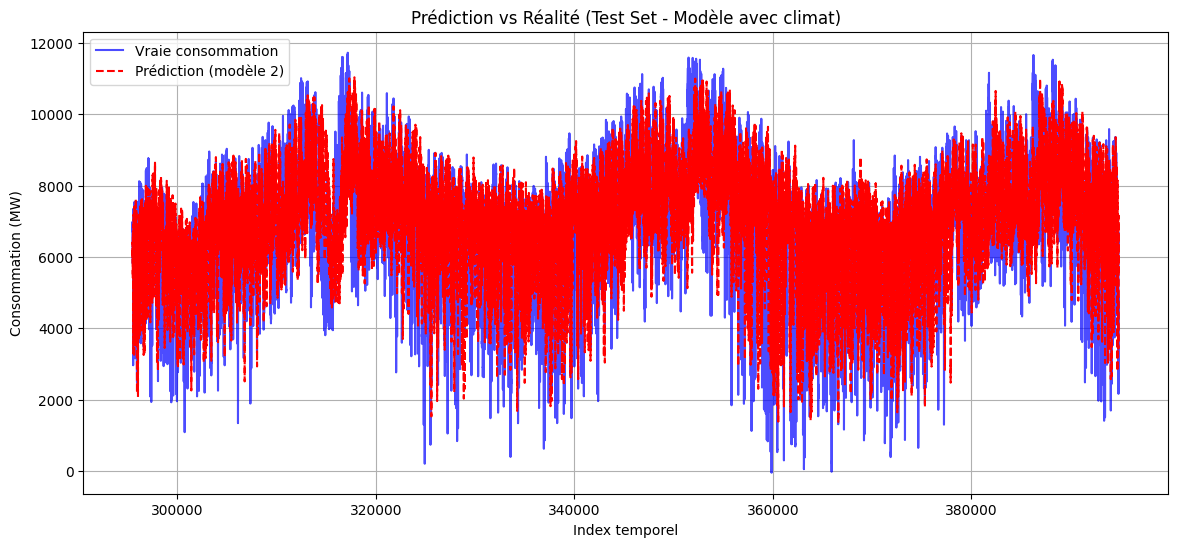

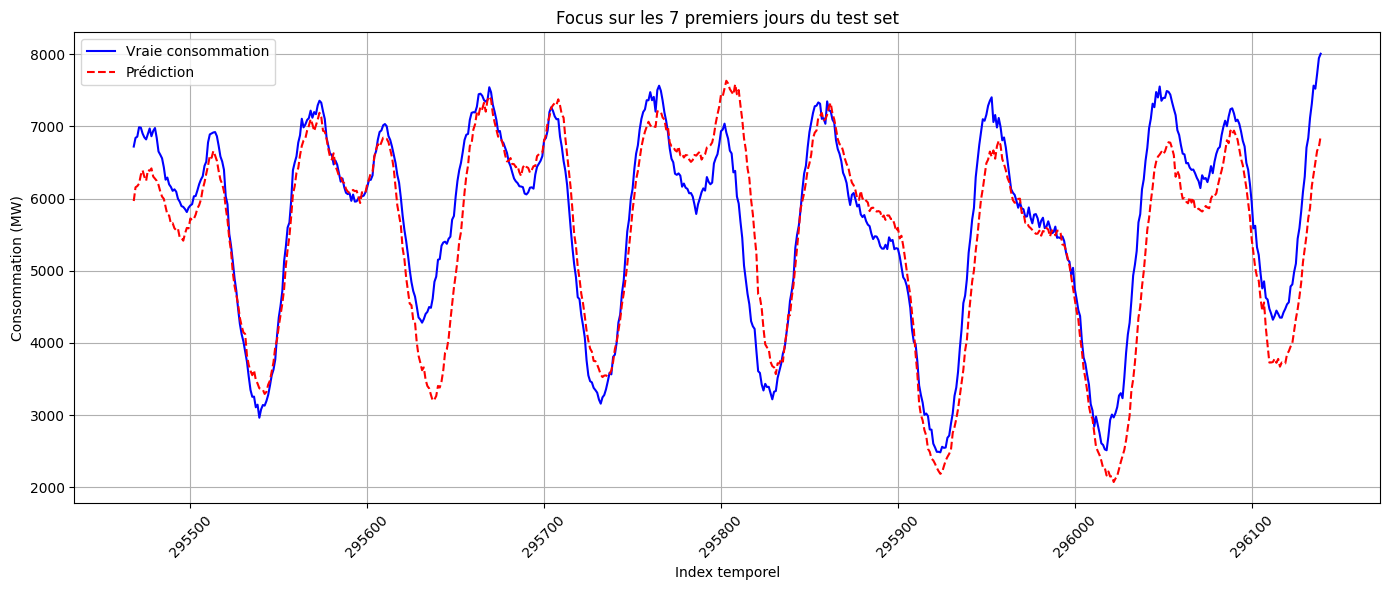

In [34]:
# Code here 
%pip install matplotlib 
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))
plt.plot(y_test_cl.index, y_test_cl, label='Vraie consommation', color='blue', alpha=0.7)
plt.plot(y_test_cl.index, y_pred_2, label='Prédiction (modèle 2)', color='red', linestyle='--')
plt.title("Prédiction vs Réalité (Test Set - Modèle avec climat)")
plt.xlabel("Index temporel")
plt.ylabel("Consommation (MW)")
plt.legend()
plt.grid(True)
plt.show()

#7 premiers jours
first_7_days_indices = y_test_cl.index[:7 * 24 * 4]  # 7 jours * 24h * 4 (15 min)
first_7_days_y_test = y_test_cl.loc[first_7_days_indices]
first_7_days_y_pred = y_pred_2.loc[first_7_days_indices]

plt.figure(figsize=(14, 6))
plt.plot(first_7_days_indices, first_7_days_y_test, label='Vraie consommation', color='blue')
plt.plot(first_7_days_indices, first_7_days_y_pred, label='Prédiction', color='red', linestyle='--')
plt.title("Focus sur les 7 premiers jours du test set")
plt.xlabel("Index temporel")
plt.ylabel("Consommation (MW)")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Comments:
Pour le Graphique 1 (ensemble du jeu de test), la consommation prédite suit globalement la consommation réelle : les deux courbes montrent les mêmes variations d'un niveau à l'autre (périodes hautes à environ 8000 - 10000 MW, périodes plus basses autour de 5000 - 6000 MW). On remarque cependant que la courbe réelle est plus étendue que la prédiction : certains pics dépassent 11 000 MW alors que la prédiction reste plus proche de 10 000 MW. Le modèle produit des valeurs plus "lissées" que la réalité et sous-estime les extrêmes. Hypothèse : ce lissage serait lié au coef de Y_t-7Days inférieure à 1 (0,83),  qui ramène les prédictions vers la moyenne. 

Graphique 2 (7 premiers jours de test, soit 672 points). Ce zoom montre ce que le graphique global ne peut pas car trop dense : la consommation suit un cycle journalier très net, avec sept creux nocturnes (environ 2 500 - 3 500 MW) et des pics en journée (environ 7 000 - 7 500 MW). Le modèle reproduit bien cette forme et la position de ces cycles. Les écarts visibles sont de 3 types : Premièrement, des écarts de niveau, par exemple en début de période où la prédiction est inférieur d'environ 750 MW par rapport à  la realité, et en fin de période où la prédiction reste nettement sous la valeur réelle. Deuxièmement, on a des décalages de forme, par exemple vers l'indice 295 800 où la prédiction présente un pic alors que la conso réelle baisse légèrement. Troisièmement, on a des creux parfois un peu plus profonds dans la prédiction que dans la réalité.

Hypothèses possibles concernant ces écarts : les écarts s'expliquent car le modèle prédit Y_t à partir de Y_t-7Days (et de la température d'il y a 7 jours), donc toutes les particularités de la semaine précédente (jour férié, météo différente, événement ponctuel) serait transmise à la prédiction.

Conclusion : le modèle avec variables climatiques reproduit bien la forme générale et le cycle journalier, avec un très bon accord sur la première semaine (R^2 = 0,82 sur le zoom de 7 jours). Il est moins précis sur les niveaux et les valeurs extrêmes, ce qui est cohérent avec un R^2 plus modeste sur l'ensemble du tests (0,497). Son accord avec la réalité reste proche de celui du modèle sans climat, ce qui indique que les variables climatiques n'apportent qu'un gain marginal.